chatgpt

In [8]:
from bleak import BleakScanner

devices = await BleakScanner.discover(timeout=20)

for device in devices:
    print(device.name, device.address)
    

None E5:45:A3:A7:27:A6
Muse-24F0 00:55:DA:B8:24:F0
None 44:CF:0A:73:FD:68
LE_WF-1000XM5 56:DD:4E:5F:E0:E8
None 4A:F4:BC:73:92:ED
None E8:EE:CC:47:F6:31
None 6F:E5:AB:41:4F:C9


Stream: Muse
Channels: 5
Sampling rate: 256.0


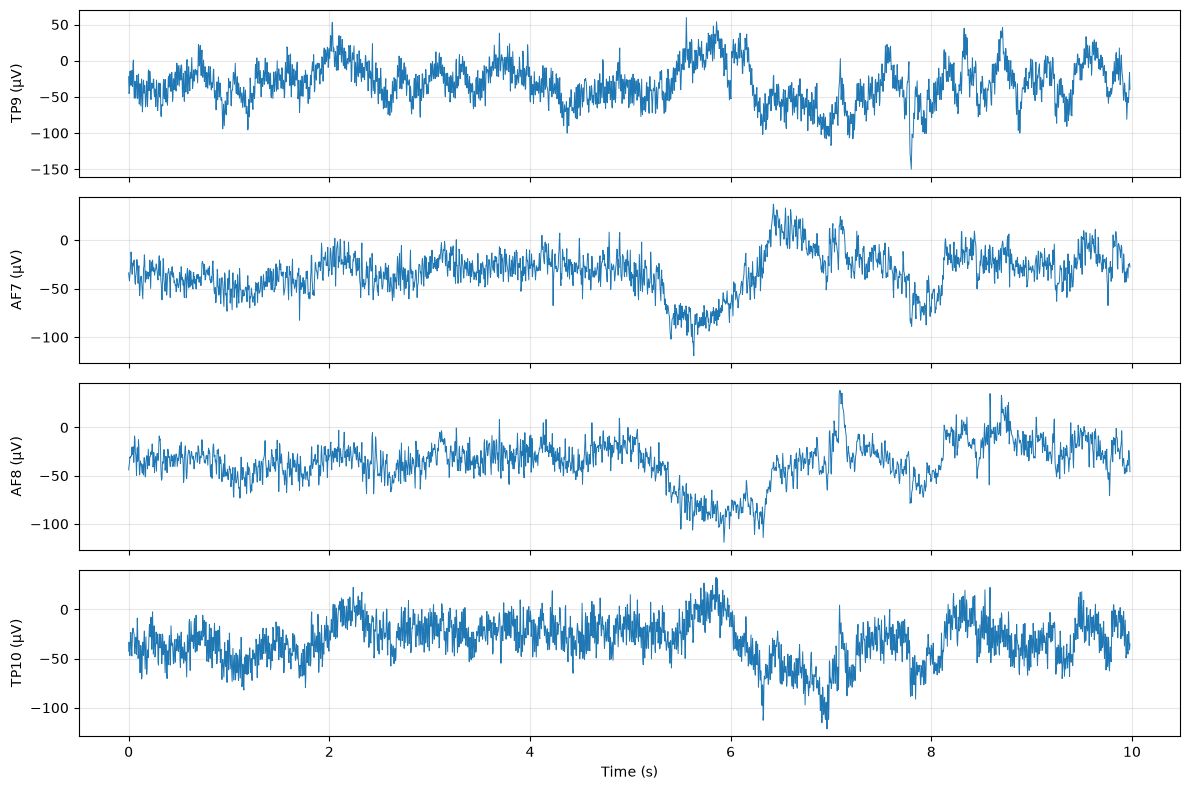

In [17]:

import time
import numpy as np
import matplotlib.pyplot as plt
from pylsl import StreamInlet, resolve_byprop

# MuseLSLのEEGストリームを検出
streams = resolve_byprop("type", "EEG", timeout=10)

if not streams:
    raise RuntimeError("EEG LSL stream not found")

stream = streams[0]
print("Stream:", stream.name())
print("Channels:", stream.channel_count())
print("Sampling rate:", stream.nominal_srate())

inlet = StreamInlet(stream)

# 10秒間取得
samples = []
timestamps = []
end_time = time.monotonic() + 10

while time.monotonic() < end_time:
    chunk, ts = inlet.pull_chunk(
        timeout=0.5, max_samples=256
    )
    samples.extend(chunk)
    timestamps.extend(ts)

if not samples:
    raise RuntimeError("No EEG samples received")

# MuseのEEG 4チャンネル
eeg = np.asarray(samples)[:, :4]
t = np.asarray(timestamps)
t = t - t[0]

names = ["TP9", "AF7", "AF8", "TP10"]

# CSV保存
np.savetxt(
    "muse2_eeg_lsl.csv",
    np.column_stack((t, eeg)),
    delimiter=",",
    header="time_s,TP9,AF7,AF8,TP10",
    comments=""
)

# 波形表示
fig, axes = plt.subplots(4, 1, figsize=(12, 8),
                         sharex=True)

for i, ax in enumerate(axes):
    ax.plot(t, eeg[:, i], linewidth=0.7)
    ax.set_ylabel(names[i] + " (µV)")
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Time (s)")
plt.tight_layout()
plt.show()


KeyboardInterrupt: 

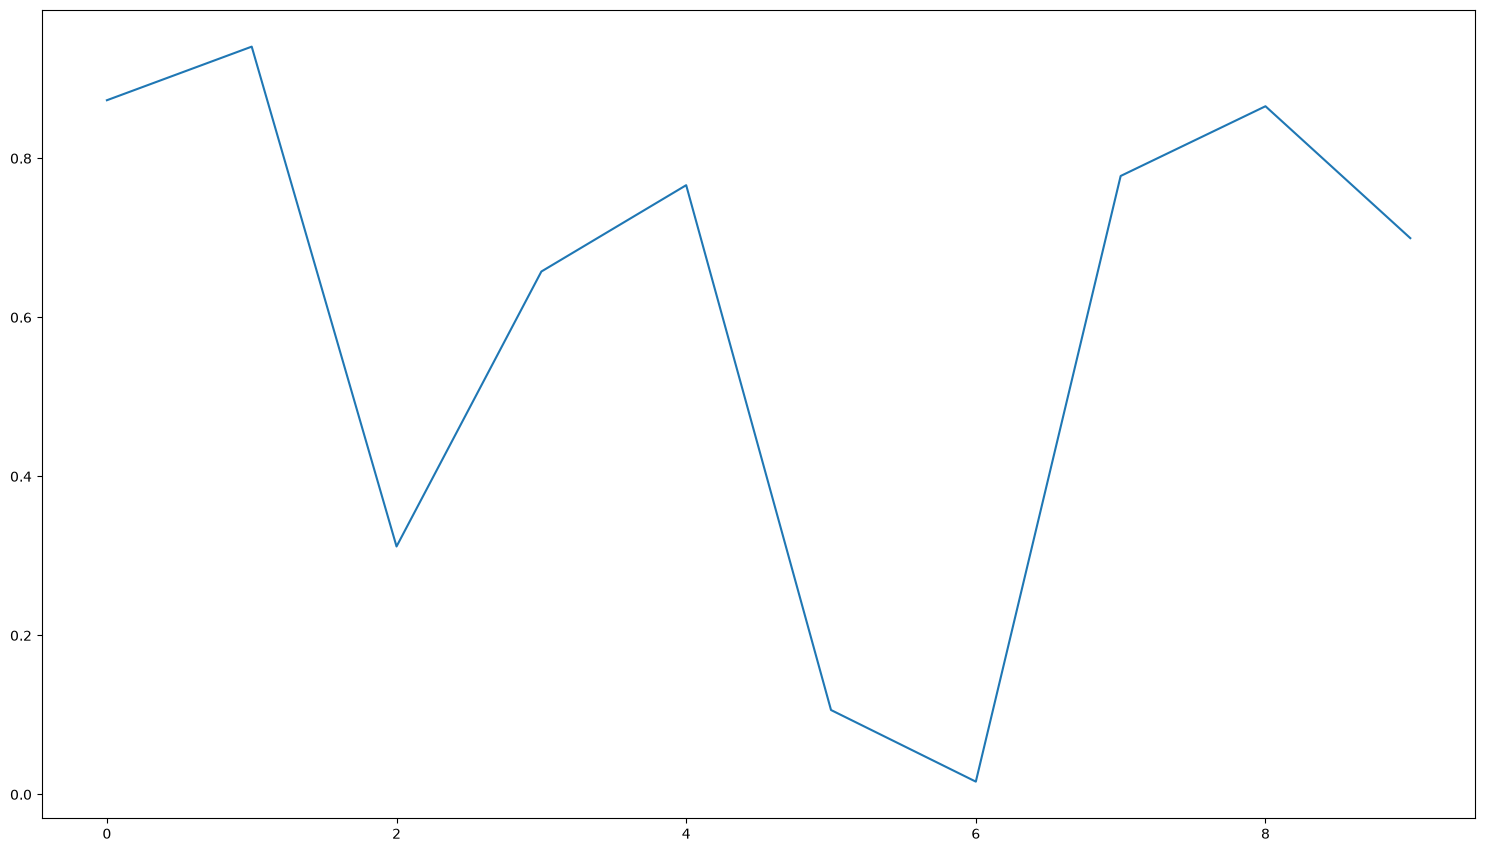

In [18]:
# https://qiita.com/shinobu_shiva/items/bdba74d37d51421c287b
import matplotlib
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt

plt.ion()

from random import randint
import time

from ipywidgets import FloatProgress
from IPython.display import display, clear_output

siz = 10
dat = np.zeros((siz, siz))

fig = plt.figure()
axe = fig.add_subplot(111)

num = 1000

for i in range(num):
    clear_output(wait = True)
    
    data = np.random.rand(10)
    axe.plot(data)
    
    fig.set_size_inches(18.5, 10.5)
    display(fig)
#     time.sleep(.2)
    axe.cla()


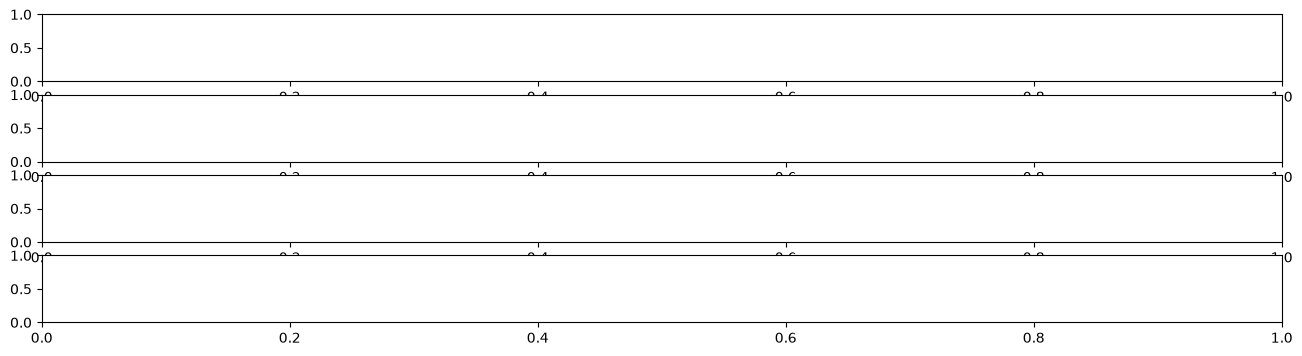

In [40]:
fig, axes= plt.subplots(4,1, figsize=(16,4))

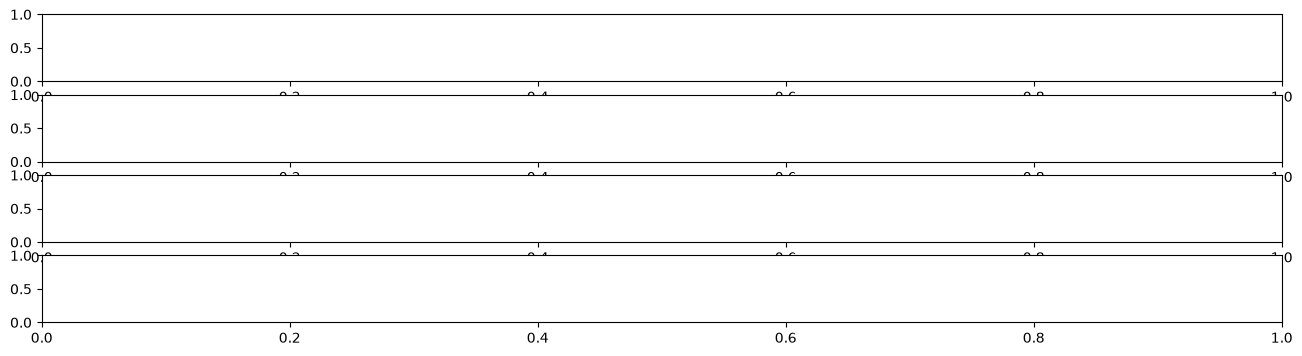

[[-64.94140625, -48.828125, -42.96875, -45.41015625, 0.0], [-47.8515625, -41.9921875, -24.90234375, -30.2734375, 0.0], [-22.4609375, -29.78515625, -20.5078125, -25.87890625, 0.0], [-15.13671875, -27.83203125, -34.66796875, -18.06640625, 0.0], [-49.31640625, -38.57421875, -43.45703125, -26.3671875, 0.0], [-53.7109375, -51.26953125, -30.2734375, -25.87890625, 0.0], [-30.2734375, -42.48046875, -18.5546875, -25.390625, 0.0], [-45.8984375, -29.296875, -30.76171875, -47.8515625, 0.0], [-64.453125, -31.73828125, -36.1328125, -46.38671875, 0.0], [-60.05859375, -35.15625, -29.78515625, -34.66796875, 0.0], [-37.59765625, -29.78515625, -25.390625, -40.52734375, 0.0], [-3.41796875, -25.87890625, -30.76171875, -34.1796875, 0.0], [-12.20703125, -43.45703125, -48.33984375, -19.04296875, 0.0], [-35.15625, -39.55078125, -37.109375, -13.671875, 0.0], [-19.53125, -15.13671875, -12.6953125, -18.06640625, 0.0], [-4.8828125, -18.5546875, -16.11328125, -32.2265625, 0.0], [-13.671875, -31.25, -21.97265625, -2

In [43]:


# fig = plt.figure()
# axe = fig.add_subplot(111)
# fig.set_size_inches(18.5, 10.5)

# MuseLSLのEEGストリームを検出
streams = resolve_byprop("type", "EEG", timeout=10)

if not streams:
    raise RuntimeError("EEG LSL stream not found")

stream = streams[0]
print("Stream:", stream.name())
print("Channels:", stream.channel_count())
print("Sampling rate:", stream.nominal_srate())

inlet = StreamInlet(stream)

# 10秒間取得
samples = []
timestamps = []
end_time = time.monotonic() + 10

while time.monotonic() < end_time:
    chunk, ts = inlet.pull_chunk(
        timeout=0.5, max_samples=256
    )
    samples.extend(chunk)
    timestamps.extend(ts)

    # matplotlib
    clear_output(wait = True)

    for i in range(4):
        axes[i].plot([j[i] for j in chunk], ts)
        axes[i].cla()
        
    # axe.plot(chunk, ts)
    display(fig)
    # axe.cla()

print(chunk)

if not samples:
    raise RuntimeError("No EEG samples received")

# MuseのEEG 4チャンネル
eeg = np.asarray(samples)[:, :4]
t = np.asarray(timestamps)
t = t - t[0]

names = ["TP9", "AF7", "AF8", "TP10"]



In [35]:
len(ts)

144

In [36]:
len([i[1] for i in chunk])


144